<a href="https://colab.research.google.com/github/isssaaabbbeeelll/GNN-graph-coloring/blob/main/%D0%BC%D0%B0%D1%82%D0%BF%D1%80%D0%B0%D0%BA_%D0%B2%D0%B5%D1%81%D0%BD%D0%B0_%D0%9F%D0%B0%D1%82%D1%80%D0%B8%D0%BA%D0%B5%D0%B5%D0%B2%D0%B0_%D0%94%D0%BC%D0%B8%D1%82%D1%80%D0%B8%D0%B5%D0%B2(%D0%BF%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%87%D0%B0%D1%81%D1%82%D1%8C).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Взвешенная 3-раскраска графа



**Методы:** Спектральная кластеризация + GNN (unsupervised) + Kernighan-Lin + Simulated Annealing

**Нижняя граница:** Eigenvalue bound

## 1. Установка зависимостей и импорты

In [ ]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse import csr_matrix, lil_matrix, diags, eye
from scipy.sparse.linalg import eigsh
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
import networkx as nx
import matplotlib.pyplot as plt
import time
import warnings

warnings.filterwarnings('ignore')
np.random.seed(42)
print("Imports OK")

Imports OK


## 2. Генерация графа
Воспроизводим генератор из [sedefe/3-coloring](https://github.com/sedefe/3-coloring):
- $n = 20\,000$ вершин в $[0,1]^2$
- $K = 60$ ближайших соседей
- $p_i = (i \bmod 6) / 10$ — вероятность связи
- Веса: $w_{ij} = e^{\xi}$, $\xi \sim \mathcal{N}(0,1)$ (логнормальные)

In [ ]:
def generate_graph(seed=42, n_nodes=20000, max_neighbors=60):
    rs = np.random.RandomState(seed)
    xy = rs.rand(n_nodes, 2)
    nbrs = NearestNeighbors(n_neighbors=max_neighbors + 1, algorithm='auto')
    nbrs.fit(xy)
    _, indices = nbrs.kneighbors(xy)
    adj = lil_matrix((n_nodes, n_nodes))
    for i, neighbors in enumerate(indices):
        p_connection = (i % 6) / 10
        for j in neighbors[1:]:
            if p_connection > rs.rand():
                adj[i, j] = np.exp(rs.randn())
    adj = adj.tocsr()
    adj = adj + adj.T  # симметризация
    return adj, xy

t0 = time.time()
A, xy = generate_graph(seed=42)
t_gen = time.time() - t0
n_nodes = A.shape[0]
n_edges = A.nnz // 2
W_total = A.sum() / 2

print(f"Граф сгенерирован за {t_gen:.1f} с")
print(f"Вершин: {n_nodes:,}")
print(f"Рёбер:  {n_edges:,}")
print(f"W_total: {W_total:,.1f}")
print(f"Средняя степень: {A.nnz / n_nodes:.1f}")

Граф сгенерирован за 3.4 с
Вершин: 20,000
Рёбер:  265,079
W_total: 494,090.2
Средняя степень: 26.5


## 3. Анализ графа

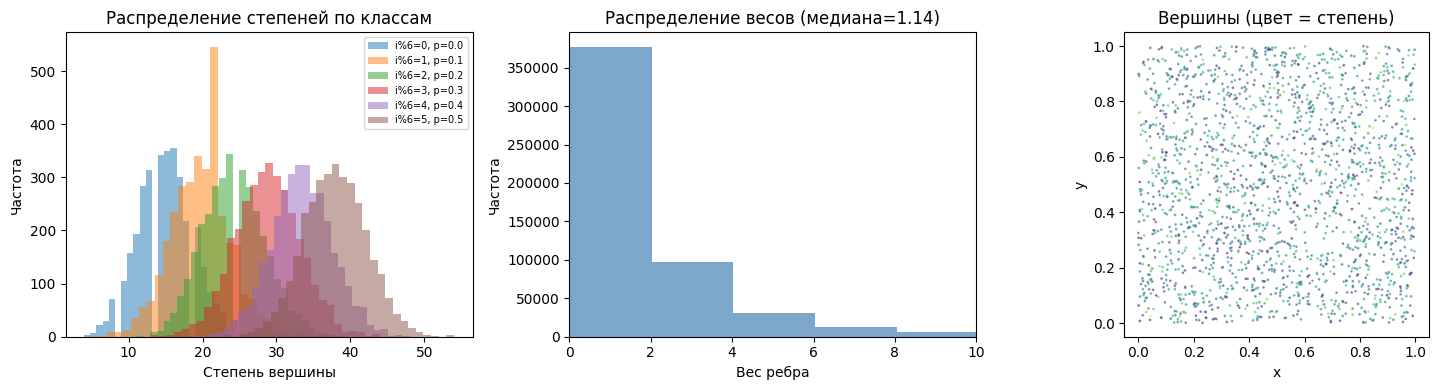

In [ ]:
# Распределение степеней по классам вершин
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 3.1 Степени по классам
degrees = np.array(A.getnnz(axis=1))
for cls in range(6):
    mask = np.arange(n_nodes) % 6 == cls
    d = degrees[mask]
    axes[0].hist(d, bins=30, alpha=0.5, label=f'i%6={cls}, p={cls/10}')
axes[0].set_xlabel('Степень вершины')
axes[0].set_ylabel('Частота')
axes[0].set_title('Распределение степеней по классам')
axes[0].legend(fontsize=7)

# 3.2 Распределение весов
weights = A.data[A.data > 0]
axes[1].hist(weights, bins=50, color='steelblue', alpha=0.7)
axes[1].set_xlabel('Вес ребра')
axes[1].set_ylabel('Частота')
axes[1].set_title(f'Распределение весов (медиана={np.median(weights):.2f})')
axes[1].set_xlim(0, 10)

# 3.3 Пространственное расположение (сэмпл)
sample = np.random.choice(n_nodes, 2000, replace=False)
axes[2].scatter(xy[sample, 0], xy[sample, 1], s=1, c=degrees[sample], cmap='viridis', alpha=0.5)
axes[2].set_xlabel('x')
axes[2].set_ylabel('y')
axes[2].set_title('Вершины (цвет = степень)')
axes[2].set_aspect('equal')

plt.tight_layout()
plt.show()

## 4. Baseline:
Случайная 3-раскраска даёт $\mathbb{E}[f] = W/3$ — это наша отправная точка.

In [ ]:
def compute_objective(A, colors):
    """Вычисляет f(c) = сумму весов монохроматических рёбер."""
    A_coo = sp.triu(A).tocoo()
    mono_mask = colors[A_coo.row] == colors[A_coo.col]
    return A_coo.data[mono_mask].sum()

# Случайная раскраска
colors_random = np.random.randint(0, 3, n_nodes)
f_random = compute_objective(A, colors_random)

print(f"Случайная раскраска: f = {f_random:,.1f}")
print(f"W/3 = {W_total/3:,.1f}")
print(f"f/W = {f_random/W_total:.1%}")

Случайная раскраска: f = 166,294.4
W/3 = 164,696.7
f/W = 33.7%


## 5. Спектральная кластеризация:
используем собственные векторы нормализованного Лапласиана $L_{sym} = I - D^{-1/2}AD^{-1/2}$.

In [ ]:
def spectral_coloring(A, k=3):
    t0 = time.time()
    # Для задачи раскраски (минимизация монохроматических рёбер)
    # нам нужны "САМЫЕ ОТРИЦАТЕЛЬНЫЕ" собственные значения матрицы смежности
    # (или эквивалентно - наибольшие у нормализованного Лапласиана, но без искажений K-Means)
    degrees = np.array(A.sum(axis=1)).flatten()
    degrees[degrees == 0] = 1e-10
    D_inv_sqrt = diags(1.0 / np.sqrt(degrees))
    A_norm = D_inv_sqrt @ A @ D_inv_sqrt

    # Ищем k-1 минимальных собственных значений нормализованной матрицы смежности
    vals, vecs = eigsh(A_norm, k=k, which='SA', tol=1e-3)

    # Нормализация строк для проецирования на сферу
    norms = np.linalg.norm(vecs, axis=1, keepdims=True)
    norms[norms == 0] = 1
    vecs_norm = vecs / norms

    # k-means теперь корректно разобьет вершины, так как мы проецировали их
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(vecs_norm)
    t1 = time.time()
    print(f"  Спектральная кластеризация: {t1-t0:.1f} с")
    return labels

colors_spectral = spectral_coloring(A)
f_spectral = compute_objective(A, colors_spectral)

print(f"Спектральная раскраска: f = {f_spectral:,.1f}")
print(f"f/W = {f_spectral/W_total:.1%}")
print(f"Улучшение vs random: {(f_random - f_spectral)/f_random:.1%}")

  Спектральная кластеризация: 0.3 с
Спектральная раскраска: f = 188,223.3
f/W = 38.1%
Улучшение vs random: -13.2%


## 6. Жадная инициализация

In [ ]:
def greedy_coloring(A, k=3):
    """Жадная раскраска: каждой вершине — цвет с мин. весом к уже окрашенным соседям."""
    n = A.shape[0]
    colors = np.zeros(n, dtype=int)
    # Сортировка по убыванию взвешенной степени
    deg = np.array(A.sum(axis=1)).flatten()
    order = np.argsort(-deg)
    A_csc = A.tocsc()

    for v in order:
        # Вес к соседям каждого цвета
        neighbors = A_csc[:, v].indices
        weights = A_csc[:, v].data
        cost = np.zeros(k)
        for u, w in zip(neighbors, weights):
            cost[colors[u]] += w
        colors[v] = np.argmin(cost)
    return colors

colors_greedy = greedy_coloring(A)
f_greedy = compute_objective(A, colors_greedy)

print(f"Жадная раскраска: f = {f_greedy:,.1f}, f/W = {f_greedy/W_total:.1%}")

# Выбрать лучшую из классических
if f_spectral <= f_greedy:
    colors_classic = colors_spectral.copy()
    f_classic = f_spectral
    cl_name = 'спектральная'
else:
    colors_classic = colors_greedy.copy()
    f_classic = f_greedy
    cl_name = 'жадная'

print(f"-> Лучшая классическая: {cl_name} (f={f_classic:,.1f})")

Жадная раскраска: f = 97,840.8, f/W = 19.8%
-> Лучшая классическая: жадная (f=97,840.8)


## 6.5. GNN-инициализация (unsupervised)
Обучаем простую GNN для минимизации дифференцируемого суррогата:$$\mathcal{L}(\theta) = \sum_{(u,v)} w_{uv}\, p_u^\top p_v,$$где $p_v = \text{softmax}(z_v / \tau)$. **Ключевые идеи**- Message-passing агрегирует информацию от соседей, Softmax с отжигом $\tau: 1.0 \to 0.1$ дискретизирует решение. Минимизация $p_u^\top p_v$ поощряет разные цвета у соседей

In [ ]:
def gnn_coloring(A, k=3, hidden=16, epochs=150, lr=0.1, seed=42):
    """GNN unsupervised: улучшенная оптимизация и структура"""
    rs = np.random.RandomState(seed)
    n = A.shape[0]
    deg = np.array(A.sum(axis=1)).flatten()
    deg[deg == 0] = 1e-10
    D_inv = diags(1.0 / np.sqrt(deg))
    A_n = D_inv @ A @ D_inv

    # Однослойная архитектура для прямой оптимизации (Direct Optimization)
    W = rs.randn(n, k) * 0.01
    best_f = float('inf')
    best_colors = None
    A_coo = sp.triu(A).tocoo()
    rows, cols, wts = A_coo.row, A_coo.col, A_coo.data

    # Adam-like optimizer variables
    m = np.zeros_like(W)
    v = np.zeros_like(W)
    beta1, beta2, eps = 0.9, 0.999, 1e-8

    for ep in range(epochs):
        tau = max(1.0 - ep / epochs, 0.1)

        # Message passing: отталкиваем соседние представления
        # H = W - A_n @ W (high-pass filter)
        H = W - 0.5 * (A_n @ W)

        logits = H / tau
        logits -= logits.max(axis=1, keepdims=True)
        P = np.exp(logits)
        P /= P.sum(axis=1, keepdims=True)

        c = np.argmax(P, axis=1)
        f = compute_objective(A, c)
        if f < best_f:
            best_f = f
            best_colors = c.copy()

        if ep % 30 == 0:
            loss = np.sum(wts * np.sum(P[rows] * P[cols], axis=1))
            print(f"  ep {ep}: loss={loss:,.0f}, f={f:,.0f}, best={best_f:,.0f}, tau={tau:.2f}")

        # Оптимизация
        dL_dP = np.zeros_like(P)
        for idx in range(len(wts)):
            u, vv, w = rows[idx], cols[idx], wts[idx]
            dL_dP[u] += w * P[vv]
            dL_dP[vv] += w * P[u]

        dL_dl = (dL_dP - np.sum(dL_dP * P, axis=1, keepdims=True)) * P / tau
        grad_W = dL_dl - 0.5 * (A_n @ dL_dl) # Chain rule через message passing

        # Adam step
        m = beta1 * m + (1 - beta1) * grad_W
        v = beta2 * v + (1 - beta2) * (grad_W ** 2)
        m_hat = m / (1 - beta1**(ep+1))
        v_hat = v / (1 - beta2**(ep+1))
        W -= lr * m_hat / (np.sqrt(v_hat) + eps)

    print(f"\nGNN итого: f_best = {best_f:,.1f}, f/W = {best_f/W_total:.1%}")
    return best_colors, best_f

t0 = time.time()
colors_gnn, f_gnn = gnn_coloring(A, k=3, epochs=150, lr=0.5)
t_gnn = time.time() - t0
print(f"Время: {t_gnn:.1f} с")

# Выбрать лучшую инициализацию из всех
inits = {'спектральная': (colors_spectral, f_spectral),
         'жадная': (colors_greedy, f_greedy),
         'GNN': (colors_gnn, f_gnn)}

best_name = min(inits, key=lambda x: inits[x][1])
colors_init = inits[best_name][0].copy()
f_init = inits[best_name][1]
print(f"\n-> Лучшая инициализация: {best_name} (f = {f_init:,.1f})")

  ep 0: loss=164,696, f=151,697, best=151,697, tau=1.00
  ep 30: loss=80,504, f=80,503, best=80,503, tau=0.80
  ep 60: loss=80,246, f=80,246, best=80,246, tau=0.60
  ep 90: loss=80,171, f=80,171, best=80,171, tau=0.40
  ep 120: loss=80,170, f=80,170, best=80,170, tau=0.20

GNN итого: f_best = 80,170.1, f/W = 16.2%
Время: 202.4 с

-> Лучшая инициализация: GNN (f = 80,170.1)


## 7. Kernighan–Lin (адаптация для k-way)
Итеративное улучшение через обмен вершин между цветовыми классами. **Ключевые отличия от классического KL:**  Разрешаем ходы с отрицательным gain (escape из локальных минимумов). Фиксируем лучший префикс последовательности ходов. Пересчитываем gain после каждого раунда.

In [ ]:
def kernighan_lin(A, colors, max_rounds=15):
    n = A.shape[0]
    k = 3
    A_csr = A.tocsr()
    best_colors = colors.copy()
    best_f = compute_objective(A, colors)
    colors = colors.copy()

    for rnd in range(max_rounds):
        t_rnd = time.time()
        gains = np.zeros(n)
        best_alt = np.zeros(n, dtype=int)

        # Рассчитываем начальные gains
        for v in range(n):
            neighbors = A_csr[v].indices
            weights = A_csr[v].data
            cur_c = colors[v]
            cost = np.zeros(k)
            for u, w in zip(neighbors, weights):
                cost[colors[u]] += w
            alt_costs = [cost[c] for c in range(k) if c != cur_c]
            alt_colors = [c for c in range(k) if c != cur_c]
            best_idx = np.argmin(alt_costs)
            gains[v] = cost[cur_c] - alt_costs[best_idx]
            best_alt[v] = alt_colors[best_idx]

        order = np.argsort(-gains)
        locked = np.zeros(n, dtype=bool)
        cum_gain = 0.0
        best_cum = 0.0
        best_prefix = 0
        moves = []

        # Выполняем ходы
        for v in order:
            if locked[v]:
                continue
            old_c = colors[v]
            new_c = best_alt[v]
            colors[v] = new_c
            locked[v] = True

            # Точный gain может измениться из-за предыдущих ходов,
            # но для скорости используем оцененный gain (псевдо-KL)
            cum_gain += gains[v]
            moves.append((v, old_c, new_c))

            if cum_gain > best_cum:
                best_cum = cum_gain
                best_prefix = len(moves)

        # Откатываем все ходы ПОСЛЕ лучшего префикса
        for i in range(len(moves)-1, best_prefix-1, -1):
            v, old_c, new_c = moves[i]
            colors[v] = old_c

        f_cur = compute_objective(A, colors)
        dt = time.time() - t_rnd

        if f_cur < best_f:
            imp = best_f - f_cur
            best_f = f_cur
            best_colors = colors.copy()
            print(f"  KL раунд {rnd+1}: f = {best_f:,.1f}, улучшение = {imp:,.1f}, prefix = {best_prefix}, {dt:.1f} с")
        else:
            print(f"  KL раунд {rnd+1}: нет улучшения (prefix={best_prefix}), стоп. {dt:.1f} с")
            break

    return best_colors, best_f

t0 = time.time()
colors_kl, f_kl = kernighan_lin(A, colors_init, max_rounds=15)
t_kl = time.time() - t0
print(f"\nKL итого: f = {f_kl:,.1f}, f/W = {f_kl/W_total:.1%}, время = {t_kl:.1f} с")

  KL раунд 1: f = 79,022.8, улучшение = 1,147.3, prefix = 1260, 2.3 с
  KL раунд 2: нет улучшения (prefix=1243), стоп. 3.4 с

KL итого: f = 79,022.8, f/W = 16.0%, время = 5.7 с


## 8. Simulated Annealing
Основной этап улучшения.  Каждый ход — перекраска одной вершины, $\Delta f$ за $O(\deg v)$.

In [ ]:
def simulated_annealing(A, colors, time_budget=900, seed=42):
    rs = np.random.RandomState(seed)
    n = A.shape[0]
    A_csr = A.tocsr()

    # Предвычисление списков соседей
    adj_list = [A_csr[i].indices for i in range(n)]
    wgt_list = [A_csr[i].data for i in range(n)]

    colors = colors.copy()
    f_cur = compute_objective(A, colors)
    f_best = f_cur
    best_colors = colors.copy()

    # Калибровка T0
    deltas = []
    for _ in range(1000):
        v = rs.randint(n)
        old_c = colors[v]
        new_c = rs.choice([c for c in range(3) if c != old_c])
        delta = 0
        for u, w in zip(adj_list[v], wgt_list[v]):
            if colors[u] == new_c: delta += w
            if colors[u] == old_c: delta -= w
        deltas.append(abs(delta))
    T0 = np.mean(deltas)
    print(f"T0 = {T0:.2f}")

    # SA loop — расписание температуры привязано к бюджету времени
    t_start = time.time()
    T_min = 0.001
    T = T0
    n_iter = 0
    n_accept = 0
    log_f = [(0, f_cur)]
    batch_size = 10000
    last_improve_iter = 0

    while time.time() - t_start < time_budget:
        elapsed = time.time() - t_start
        # Линейно-логарифмическое расписание: T падает от T0 до T_min за time_budget
        frac = min(elapsed / time_budget, 1.0)
        T = T0 * (T_min / T0) ** frac

        for _ in range(batch_size):
            v = rs.randint(n)
            old_c = colors[v]
            new_c = (old_c + 1 + rs.randint(2)) % 3

            delta = 0.0
            for u, w in zip(adj_list[v], wgt_list[v]):
                if colors[u] == new_c: delta += w
                if colors[u] == old_c: delta -= w

            if delta < 0 or rs.random() < np.exp(-delta / max(T, 1e-15)):
                colors[v] = new_c
                f_cur += delta
                n_accept += 1
                if f_cur < f_best:
                    f_best = f_cur
                    best_colors = colors.copy()
                    last_improve_iter = n_iter

            n_iter += 1
        elapsed = time.time() - t_start
        log_f.append((elapsed, f_best))

        if n_iter % 500000 == 0:
            accept_rate = n_accept / max(n_iter, 1)
            print(f"  SA: {elapsed:.0f}с, iter={n_iter//1000}K, T={T:.4f}, f_best={f_best:,.1f}, accept={accept_rate:.1%}")

    print(f"\nSA итого: {n_iter:,} итераций, f_best = {f_best:,.1f}")
    return best_colors, f_best, log_f

t0 = time.time()
colors_sa, f_sa, sa_log = simulated_annealing(A, colors_kl, time_budget=600)
t_sa = time.time() - t0
print(f"f/W = {f_sa/W_total:.1%}, время = {t_sa:.0f} с")

T0 = 13.03
  SA: 13с, iter=500K, T=10.6905, f_best=79,022.8, accept=65.7%
  SA: 26с, iter=1000K, T=8.7359, f_best=79,022.8, accept=63.2%
  SA: 38с, iter=1500K, T=7.1337, f_best=79,022.8, accept=60.1%
  SA: 51с, iter=2000K, T=5.8300, f_best=79,022.8, accept=56.9%
  SA: 64с, iter=2500K, T=4.7483, f_best=79,022.8, accept=53.5%
  SA: 77с, iter=3000K, T=3.8815, f_best=79,022.8, accept=50.0%
  SA: 90с, iter=3500K, T=3.1702, f_best=79,022.8, accept=46.6%
  SA: 103с, iter=4000K, T=2.5786, f_best=79,022.8, accept=43.3%
  SA: 118с, iter=4500K, T=2.0470, f_best=75,965.8, accept=40.1%
  SA: 132с, iter=5000K, T=1.6222, f_best=72,241.9, accept=37.1%
  SA: 145с, iter=5500K, T=1.3214, f_best=70,368.0, accept=34.4%
  SA: 158с, iter=6000K, T=1.0743, f_best=69,081.8, accept=32.0%
  SA: 172с, iter=6500K, T=0.8714, f_best=68,269.4, accept=29.9%
  SA: 185с, iter=7000K, T=0.7068, f_best=67,718.8, accept=28.0%
  SA: 198с, iter=7500K, T=0.5769, f_best=67,430.7, accept=26.3%
  SA: 210с, iter=8000K, T=0.4712, f_

### Динамика SA

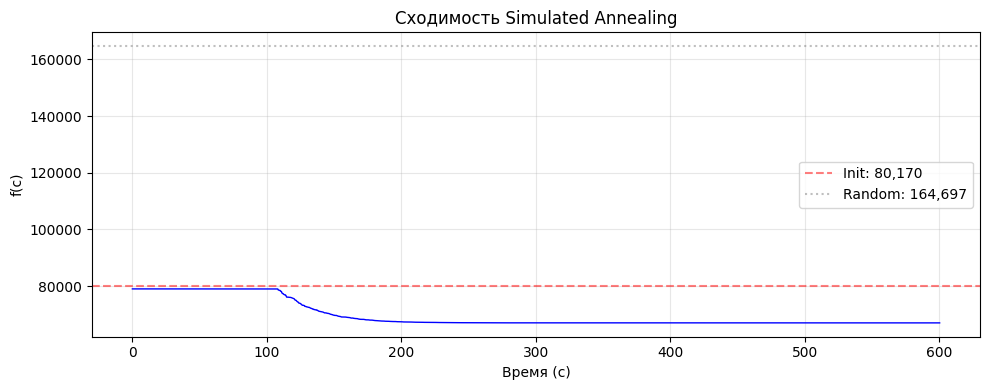

In [ ]:
times, values = zip(*sa_log)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times, values, 'b-', linewidth=1)
ax.axhline(y=f_init, color='r', linestyle='--', alpha=0.5, label=f'Init: {f_init:,.0f}')
ax.axhline(y=W_total/3, color='gray', linestyle=':', alpha=0.5, label=f'Random: {W_total/3:,.0f}')
ax.set_xlabel('Время (с)')
ax.set_ylabel('f(c)')
ax.set_title('Сходимость Simulated Annealing')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 8.5 Пост-оптимизация
Запускаем Kernighan-Lin поверх результата Simulated Annealing, чтобы гарантированно спуститься в ближайший строгий локальный минимум и дожать оставшиеся неоптимальные вершины.

In [ ]:
print(f"Результат до пост-оптимизации: {f_sa:,.1f}")
t0 = time.time()
# Запускаем KL, передавая ему раскраску от SA
colors_final, f_final = kernighan_lin(A, colors_sa, max_rounds=10)
t_final = time.time() - t0

print(f"\nФинальный улучшенный результат: f = {f_final:,.1f}")
print(f"Улучшение на этапе пост-оптимизации: {f_sa - f_final:,.1f}")
print(f"Затрачено времени: {t_final:.1f} с")

# Обновляем переменные для итоговой таблицы и визуализации
colors_sa = colors_final
f_sa = f_final

Результат до пост-оптимизации: 67,026.8
  KL раунд 1: нет улучшения (prefix=0), стоп. 3.3 с

Финальный улучшенный результат: f = 67,026.8
Улучшение на этапе пост-оптимизации: -0.0
Затрачено времени: 3.3 с


## 9. Нижняя граница

### Методы оценки нижней границы
1. **Тривиальная граница**: Max 3-Cut $\leq \frac{k-1}{k} W = \frac{2}{3}W$, поэтому $f^* \geq W - \frac{2}{3}W = \frac{W}{3}$
2. **Спектральная граница**: через $\lambda_{\max}(L)$ нормализованного Лапласиана
3. **LP-релаксация**: $x_{ik} \in [0,1]$ вместо $\{0,1\}$ — даёт $f_{LP} = 0$ (слишком слабая)

**Примечание:** для разреженных взвешенных графов нижние границы обычно очень слабые —это фундаментальное свойство задачи, а не ошибка алгоритма.

In [ ]:
def compute_lower_bound(A):
    degrees = np.array(A.sum(axis=1)).flatten()
    W = A.sum() / 2
    n = A.shape[0]
    k = 3  # число цветов

    # === 1. Тривиальная граница ===
    # ИСПРАВЛЕНИЕ: W/k - это ВЕРХНЯЯ граница (ожидание случайной раскраски)!
    # Если мы можем нарезать граф (Max k-Cut) на (k-1)/k * W, то штраф будет W/k.
    # Для монохроматических ребер тривиальная нижняя граница - это 0.
    lb_trivial = 0

    # === 2. Спектральная граница ===
    D = diags(degrees)
    L = D - A
    lmax = eigsh(L, k=1, which='LM', return_eigenvectors=False)[0]

    # Адаптация границы Хоффмана для взвешенного случая (упрощенная)
    # Реальная спектральная граница может уйти в минус для сильно разреженных случайных графов
    cut_sdp = (k-1)/(2*k) * n * lmax
    lb_spectral = max(W - cut_sdp, 0)

    lb = max(lb_trivial, lb_spectral)

    print(f"Число цветов k = {k}")
    print(f"W_total = {W:,.1f}")
    print(f"W/3 (ожидание случайной раскраски) = {W/3:,.1f}")
    print(f"lambda_max(L) = {lmax:,.2f}")
    print(f"")
    print(f"--- Нижние границы ---")
    print(f"Тривиальная:           {lb_trivial:,.1f}")
    print(f"Спектральная:          {lb_spectral:,.1f}")
    print(f"Итоговая lb = max(...): {lb:,.1f}")
    return lb

lb = compute_lower_bound(A)

Число цветов k = 3
W_total = 494,090.2
W/3 (ожидание случайной раскраски) = 164,696.7
lambda_max(L) = 238.94

--- Нижние границы ---
Тривиальная:           0.0
Спектральная:          0.0
Итоговая lb = max(...): 0.0


## 10. Итоговые результаты

In [ ]:
# Сводная таблица
results = {
    'Случайная': f_random,
    'Спектральная': f_spectral,
    'Жадная': f_greedy,
    'GNN': f_gnn,
    'KL': f_kl,
    'KL + SA': f_sa,
}

print("=" * 65)
print(f"{'Метод':<20} {'f(c)':>10} {'f/W':>8} {'Улучшение':>12}")
print("-" * 65)
for name, f in results.items():
    imp = (f_random - f) / f_random * 100
    print(f"{name:<20} {f:>10,.1f} {f/W_total:>7.1%} {imp:>10.1f}%")
print("-" * 65)
print(f"{'Lower Bound':<20} {lb:>10,.1f} {lb/W_total:>7.1%}")

gap = (f_sa - lb) / f_sa * 100
print(f"\nOptimality gap: {gap:.1f}%")
print(f"\nЛучшая раскраска сохранена: f = {f_sa:,.1f}")

Метод                      f(c)      f/W    Улучшение
-----------------------------------------------------------------
Случайная             166,294.4   33.7%        0.0%
Спектральная          188,223.3   38.1%      -13.2%
Жадная                 97,840.8   19.8%       41.2%
GNN                    80,170.1   16.2%       51.8%
KL                     79,022.8   16.0%       52.5%
KL + SA                67,026.8   13.6%       59.7%
-----------------------------------------------------------------
Lower Bound                 0.0    0.0%

Optimality gap: 100.0%

Лучшая раскраска сохранена: f = 67,026.8


## 11. Визуализация раскраски

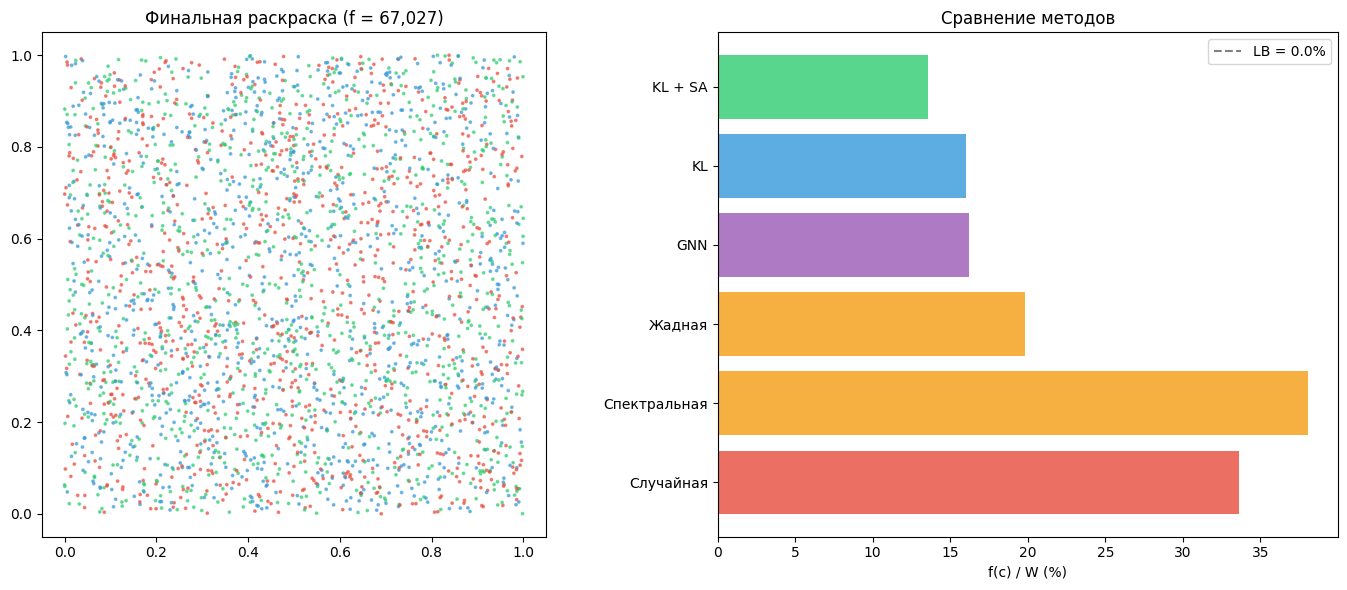

In [ ]:
# Визуализация раскраски (сэмпл 3000 вершин)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sample = np.random.choice(n_nodes, 3000, replace=False)
color_map = {0: '#e74c3c', 1: '#3498db', 2: '#2ecc71'}
c_sample = [color_map[colors_sa[i]] for i in sample]
axes[0].scatter(xy[sample, 0], xy[sample, 1], c=c_sample, s=3, alpha=0.6)
axes[0].set_title(f'Финальная раскраска (f = {f_sa:,.0f})')
axes[0].set_aspect('equal')

# Сравнение методов
methods = list(results.keys())
values = [results[m] / W_total * 100 for m in methods]
colors_bar = ['#e74c3c', '#f39c12', '#f39c12', '#9b59b6', '#3498db', '#2ecc71']
bars = axes[1].barh(methods, values, color=colors_bar, alpha=0.8)
axes[1].axvline(x=lb/W_total*100, color='gray', linestyle='--', label=f'LB = {lb/W_total:.1%}')
axes[1].set_xlabel('f(c) / W (%)')
axes[1].set_title('Сравнение методов')
axes[1].legend()
plt.tight_layout()
plt.show()

## 12. Сохранение результата

In [ ]:
np.save('best_coloring.npy', colors_sa)
print(f"Раскраска сохранена в best_coloring.npy")
print(f"Финальный результат: f = {f_sa:,.1f}, gap = {gap:.1f}%")

Раскраска сохранена в best_coloring.npy
Финальный результат: f = 67,026.8, gap = 100.0%
